# P6 — Bot detection: EDA, feature, đánh giá Isolation Forest

**Đọc trước:** toàn bộ dữ liệu ở đây là **tự tạo** bằng k6 (`datagen/traffic.js`) trên stack thật (Gateway →
order-service → outbox). Cả "người dùng" lẫn "bot" đều do chính dự án viết kịch bản, nên kết quả chỉ cho biết
model tách được **các kiểu hành vi mà ta đã giả định**, không chứng minh hiệu quả trên traffic production.

- Vòng **A**: dữ liệu huấn luyện + validation (chia theo tài khoản).
- Vòng **B**: dữ liệu kiểm tra — tài khoản khác, lần chạy k6 khác, cùng kịch bản.
- Nhãn = loại tài khoản (`human`, `botfast`, `botviewer`, `botfarm`), chỉ dùng để lấy mẫu tỉ lệ bot cho tập
  train, chọn ngưỡng và đánh giá. Model không thấy nhãn khi học.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' if (ROOT / 'data').exists() else ROOT / 'training' / 'data'
REPORTS = DATA.parent / 'reports'
FEATURES = ['buyer_adds_1m', 'buyer_adds_10m', 'device_adds_1m', 'secs_since_prev_add', 'device_accounts_24h',
            'account_age_hours', 'viewed_event', 'secs_since_view', 'quantity', 'item_count', 'buyer_events_1h',
            'has_device']
a = pd.read_csv(DATA / 'features_a.csv'); b = pd.read_csv(DATA / 'features_b.csv')
scored = pd.read_csv(REPORTS / 'scored.csv')
metrics = json.loads((REPORTS / 'metrics.json').read_text(encoding='utf-8'))
pd.set_option('display.width', 160)

## 1. Dữ liệu

In [2]:
summary = pd.concat([a, b]).groupby(['round', 'kind']).agg(
    events=('order_id', 'size'), accounts=('buyer_id', 'nunique')).unstack(0)
summary

events      accounts     
round          A    B        A    B
kind                               
botfarm       33   33       24   24
botfast      379  362       18   18
botviewer     96   96       14   14
human        262  277      200  200

Bot sinh nhiều lần thêm giỏ hơn người dùng (đặc biệt `botfast` xoay giỏ). Isolation Forest giả định
bất thường là thiểu số nên tập train được lấy mẫu để bot ≈ 10% lần thêm giỏ; model học trên tỉ lệ tự nhiên
được so sánh ở mục 4.

In [3]:
pd.Series(metrics['training']).to_frame('value')

,value
train_events_before_sampling,571
train_bot_share_before_sampling,0.6515
train_events,220
validation_events,199
test_events,768
train_bot_share,0.0955
train_accounts,162
test_accounts,256
estimator,"{'n_estimators': 300, 'max_samples': 'auto', '..."
train_bot_share_target,0.1


## 2. EDA — phân bố feature theo loại tài khoản (vòng A)

In [4]:
a.groupby('kind')[FEATURES].median().T.round(2)

kind,botfarm,botfast,botviewer,human
buyer_adds_1m,1.00,11.00,4.00,1.00
buyer_adds_10m,1.00,11.00,4.00,1.00
device_adds_1m,2.00,1.00,4.00,1.00
secs_since_prev_add,3600.00,0.47,1.31,3600.00
device_accounts_24h,5.00,1.00,1.00,1.00
account_age_hours,30.11,32.98,38.71,493.99
viewed_event,1.00,0.00,1.00,1.00
secs_since_view,45.00,0.00,1.49,29.68
quantity,2.00,2.00,3.00,2.00
item_count,1.00,1.00,1.00,1.00


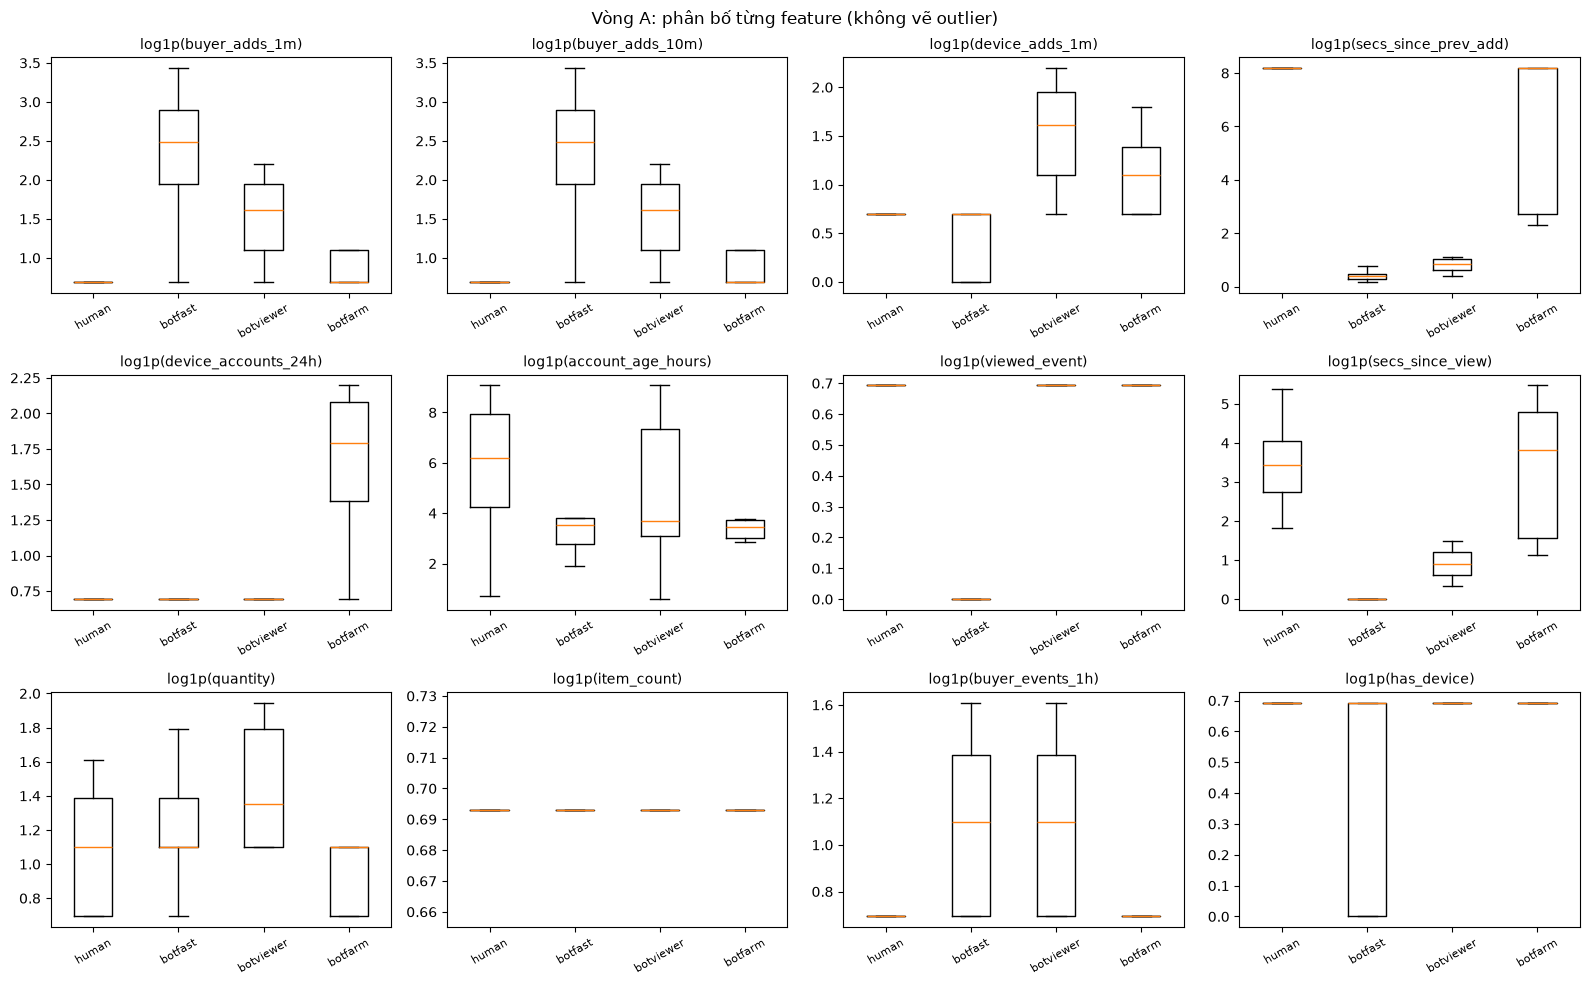

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
kinds = ['human', 'botfast', 'botviewer', 'botfarm']
for ax, feature in zip(axes.flat, FEATURES):
    data = [np.log1p(a.loc[a.kind == k, feature].fillna(0).clip(lower=0)) for k in kinds]
    ax.boxplot(data, tick_labels=kinds, showfliers=False)
    ax.set_title(f'log1p({feature})', fontsize=10)
    ax.tick_params(axis='x', labelrotation=30, labelsize=8)
fig.suptitle('Vòng A: phân bố từng feature (không vẽ outlier)')
fig.tight_layout()

Quan sát:
- `botfast`: tốc độ thêm giỏ (`buyer_adds_1m`, `secs_since_prev_add` rất nhỏ), không xem trang, một nửa không
  gửi thiết bị — dễ tách nhất.
- `botviewer`: có gọi availability (`viewed_event = 1`) nhưng `secs_since_view` rất nhỏ, gom nhiều sự kiện
  (`buyer_events_1h`), số lượng lớn.
- `botfarm`: từng tài khoản thêm giỏ ít như người dùng; tín hiệu chính là `device_accounts_24h` và tài khoản mới.
- Người dùng cũng có tài khoản mới (12%) và vài thiết bị dùng chung (gia đình) — chồng lấn có chủ đích.

## 3. Phân bố điểm bất thường

Text(0.5, 1.0, 'Vòng B (test)')

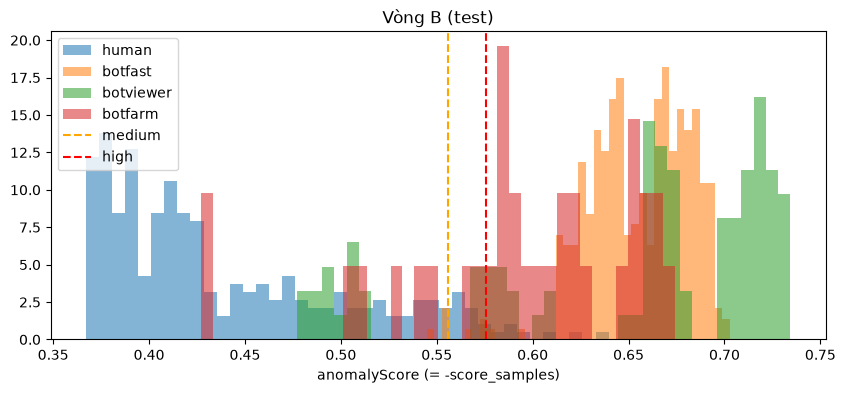

In [6]:
test = scored[scored.split == 'test']
th = metrics['thresholds']
fig, ax = plt.subplots(figsize=(10, 4))
for kind in kinds:
    ax.hist(test.loc[test.kind == kind, 'anomaly_score'], bins=40, alpha=0.55, label=kind, density=True)
ax.axvline(th['medium'], color='orange', linestyle='--', label='medium')
ax.axvline(th['high'], color='red', linestyle='--', label='high')
ax.set_xlabel('anomalyScore (= -score_samples)'); ax.legend(); ax.set_title('Vòng B (test)')

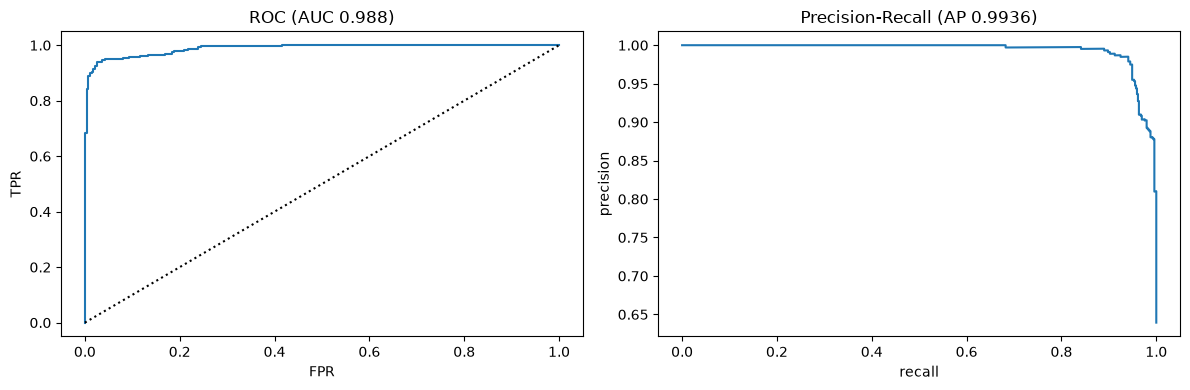

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
fpr, tpr, _ = roc_curve(test.label, test.anomaly_score)
left.plot(fpr, tpr); left.plot([0, 1], [0, 1], 'k:'); left.set_title(f"ROC (AUC {metrics['test']['roc_auc']})")
left.set_xlabel('FPR'); left.set_ylabel('TPR')
precision, recall, _ = precision_recall_curve(test.label, test.anomaly_score)
right.plot(recall, precision); right.set_title(f"Precision-Recall (AP {metrics['test']['average_precision']})")
right.set_xlabel('recall'); right.set_ylabel('precision')
fig.tight_layout()

## 4. Kết quả trên vòng B (test)

In [8]:
rows = {
    'Isolation Forest (train 10% bot)': metrics['test']['model'],
    'Isolation Forest (train tỉ lệ tự nhiên)': metrics['natural_mix_variant']['test'],
    'Luật tay (adds_1m ≥ 4 hoặc ≥ 4 tài khoản/thiết bị)': metrics['test']['baseline_rule'],
}
pd.DataFrame({name: {k: v for k, v in m.items() if k != 'high_rate_by_kind'} for name, m in rows.items()}).T

,events,bot_events,tp,fp,fn,precision,recall,f1
Isolation Forest (train 10% bot),768.0,491.0,458.0,7.0,33.0,0.9849,0.9328,0.9582
Isolation Forest (train tỉ lệ tự nhiên),768.0,491.0,65.0,9.0,426.0,0.8784,0.1324,0.2301
Luật tay (adds_1m ≥ 4 hoặc ≥ 4 tài khoản/thiết bị),768.0,491.0,384.0,0.0,107.0,1.0000,0.7821,0.8777


In [9]:
pd.DataFrame({name: m['high_rate_by_kind'] for name, m in rows.items()}).T.rename(
    columns=lambda c: f'HIGH rate · {c}')

,HIGH rate · botfarm,HIGH rate · botfast,HIGH rate · botviewer,HIGH rate · human
Isolation Forest (train 10% bot),0.7273,0.9834,0.8125,0.0253
Isolation Forest (train tỉ lệ tự nhiên),0.5758,0.0746,0.1979,0.0325
Luật tay (adds_1m ≥ 4 hoặc ≥ 4 tài khoản/thiết bị),0.6667,0.8508,0.5625,0.0000


Theo tài khoản (cách Order dùng kết quả: một lần HIGH là chặn các lần thêm sau):
`flagged_share` = tỉ lệ tài khoản bị chặn; `median_adds_before_flag` = số lần thêm giỏ đã lọt trước khi bị chặn.

In [10]:
pd.DataFrame(metrics['test']['model_accounts']['by_kind']).T

,accounts,flagged_share,median_adds_before_flag
botfarm,24.0,0.7083,0.0
botfast,18.0,1.0000,0.0
botviewer,14.0,1.0000,1.0
human,200.0,0.0350,1.0


In [11]:
print('Người dùng bị chặn (test):', metrics['test']['model_accounts']['humans_flagged'], '/',
      metrics['test']['model_accounts']['humans'])
print('Luật tay — người dùng bị chặn:', metrics['test']['baseline_accounts']['humans_flagged'])

Người dùng bị chặn (test): 7 / 200
Luật tay — người dùng bị chặn: 0


## 5. Giới hạn (trung thực)

1. **Dữ liệu tự tạo, nhãn do chính ta đặt.** Model học đúng các khác biệt mà kịch bản k6 cố ý tạo ra
   (tốc độ, xem trang, thiết bị chung, tuổi tài khoản). Bot thật sẽ bắt chước người dùng tốt hơn.
2. **Tỉ lệ bot trong tập train do ta chọn (10%)** bằng cách dùng nhãn để lấy mẫu — một bước có giám sát nhẹ.
   Ở tỉ lệ tự nhiên của kịch bản (bot chiếm đa số lần thêm giỏ) kết quả được báo cáo riêng ở mục 4.
3. **Ngưỡng chọn bằng nhãn trên validation** (≤ 1% lần thêm giỏ của người dùng bị HIGH). Production không
   có nhãn: ngưỡng cần đặt theo tỉ lệ báo động chấp nhận được và review của ADMIN.
4. **Feature dễ né:** device ID nằm ở localStorage (xóa là có ID mới), "đã xem" chỉ là một lần gọi
   availability, tốc độ có thể giả bằng cách chờ. `botfarm` cho thấy bot chậm + nhiều tài khoản khó bắt hơn hẳn.
5. **Quy mô nhỏ** (vài trăm tài khoản, vài nghìn lần thêm giỏ, một máy dev) — chưa nói gì về drift theo thời gian.
6. Thời gian "suy nghĩ" của người dùng mô phỏng là phân bố tự chọn, không đo từ người thật.